# SMS Spam Classifier

Prepare the UCI SMS Spam Collection, train a spam classifier, and compare it with a majority-class baseline on a held-out test set.

In [1]:
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

## 1. Load and deduplicate the data

The source file contains a label and a message on each line. Normalize case and whitespace
before removing duplicates so copies of the same message cannot land on both sides of the split.

In [2]:
path = Path("data/SMSSpamCollection")
rows = [
    line.split("\t", maxsplit=1)
    for line in path.read_text(encoding="utf-8").splitlines()
    if line.strip()
]
sms = pd.DataFrame(rows, columns=["label", "message"])
sms["message_key"] = sms["message"].str.lower().str.split().str.join(" ")

original_count = len(sms)
sms = sms.drop_duplicates(subset="message_key").drop(columns="message_key")
print(f"{original_count:,} raw messages, {len(sms):,} after deduplication")

counts = sms["label"].value_counts()
display(pd.DataFrame({"count": counts, "share": (counts / len(sms)).round(3)}))

5,574 raw messages, 5,159 after deduplication


,count,share
label,,
ham,4517,0.876
spam,642,0.124


## 2. Train and evaluate

Use a stratified 80/20 split to preserve the spam proportion. Fit the TF-IDF vocabulary
and logistic regression on the training set only. Use class weights to account for the
smaller spam class. Report precision, recall, and F1 for spam alongside overall accuracy.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    sms["message"], sms["label"], test_size=0.2, random_state=42, stratify=sms["label"]
)
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
classifier = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
    LogisticRegression(class_weight="balanced", max_iter=1000),
).fit(X_train, y_train)

names = ["Majority baseline", "TF-IDF + logistic regression"]
predictions = [baseline.predict(X_test), classifier.predict(X_test)]
results = pd.DataFrame(
    {
        "accuracy": [accuracy_score(y_test, pred) for pred in predictions],
        "spam precision": [
            precision_score(y_test, pred, pos_label="spam", zero_division=0)
            for pred in predictions
        ],
        "spam recall": [recall_score(y_test, pred, pos_label="spam") for pred in predictions],
        "spam F1": [f1_score(y_test, pred, pos_label="spam") for pred in predictions],
    },
    index=names,
)
display(results.round(3))

,accuracy,spam precision,spam recall,spam F1
Majority baseline,0.876,0.000,0.000,0.000
TF-IDF + logistic regression,0.983,0.917,0.945,0.931


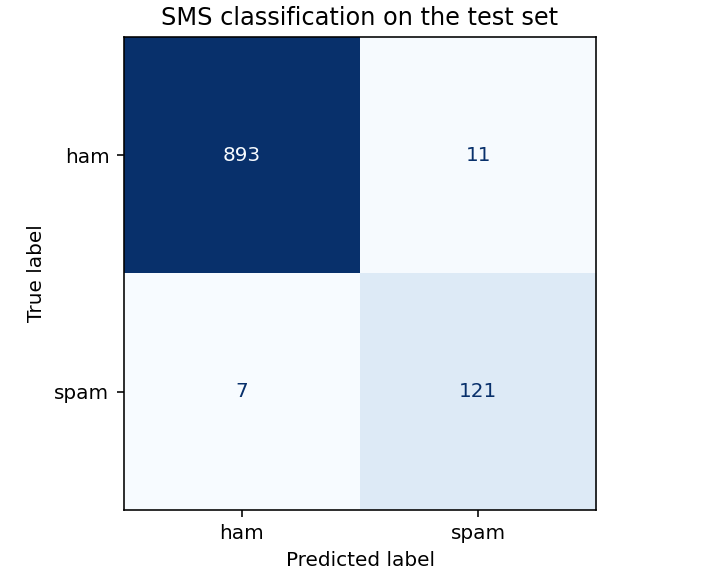

In [4]:
fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions[1], labels=["ham", "spam"], cmap="Blues",
    colorbar=False, values_format="d", ax=ax,
)
ax.set(title="SMS classification on the test set", xlabel="Predicted label", ylabel="True label")
with BytesIO() as buffer:
    fig.savefig(buffer, format="png", dpi=144)
    display(Image(data=buffer.getvalue()))
plt.close(fig)